## Visualize training and validation loss curves by manually extracting loss values at each epoch, plotting them using low-level Matplotlib functions, and analyzing learning trends without using built-in Keras visualization tools.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('heart.csv')                          
X, y = df.drop(columns='target').values.astype(float), df['target'].values

idx = np.random.default_rng(0).permutation(len(X)); a, b = int(0.6 * len(X)), int(0.8 * len(X))
tr, va, te = idx[:a], idx[a:b], idx[b:]
mu, sd = X[tr].mean(0), X[tr].std(0)                   # train stats se scaling
Xtr, ytr, Xva, yva = (X[tr] - mu) / sd, y[tr], (X[va] - mu) / sd, y[va]
print('train/val/test:', len(tr), len(va), len(te))

train/val/test: 181 61 61


In [2]:
sig = lambda z: 1 / (1 + np.exp(-z))
bce = lambda p, t: -np.mean(t * np.log(p + 1e-9) + (1 - t) * np.log(1 - p + 1e-9))    

def train(hidden, lr, epochs=300, wd=0.0, bs=32, seed=0):
    r = np.random.default_rng(seed); sizes = [Xtr.shape[1], *hidden, 1]
    W = [r.normal(0, np.sqrt(2 / m), (m, n)) for m, n in zip(sizes[:-1], sizes[1:])]; B = [np.zeros(n) for n in sizes[1:]]

    def forward(A):
        acts = [A]
        for i in range(len(W)):
            A = A @ W[i] + B[i]
            if i < len(W) - 1: A = np.maximum(A, 0)
            acts.append(A)
        return acts

    train_losses, val_losses = [], []                                  
    for ep in range(epochs):
        perm = r.permutation(len(Xtr))
        for i in range(0, len(perm), bs):                               
            j = perm[i:i + bs]; acts = forward(Xtr[j]); d = (sig(acts[-1][:, 0]) - ytr[j])[:, None] / len(j)
            for k in reversed(range(len(W))):
                gW = acts[k].T @ d + wd * W[k]; gB = d.sum(0)
                if k > 0: d = (d @ W[k].T) * (acts[k] > 0)
                W[k] -= lr * gW; B[k] -= lr * gB
        train_losses.append(bce(sig(forward(Xtr)[-1][:, 0]), ytr))      
        val_losses.append(bce(sig(forward(Xva)[-1][:, 0]), yva))        
    return train_losses, val_losses

In [3]:
train_losses, val_losses = train(hidden=(128, 128), lr=0.05)
epochs = np.arange(1, len(train_losses) + 1)
for e in [1, 10, 25, 50, 100, 200, 300]:
    print(f'epoch {e:3d}: train loss = {train_losses[e-1]:.4f} | val loss = {val_losses[e-1]:.4f}')

epoch   1: train loss = 0.4977 | val loss = 0.4487
epoch  10: train loss = 0.2630 | val loss = 0.3768
epoch  25: train loss = 0.1734 | val loss = 0.4292
epoch  50: train loss = 0.0913 | val loss = 0.5323
epoch 100: train loss = 0.0317 | val loss = 0.6855
epoch 200: train loss = 0.0095 | val loss = 0.8631
epoch 300: train loss = 0.0049 | val loss = 0.9768


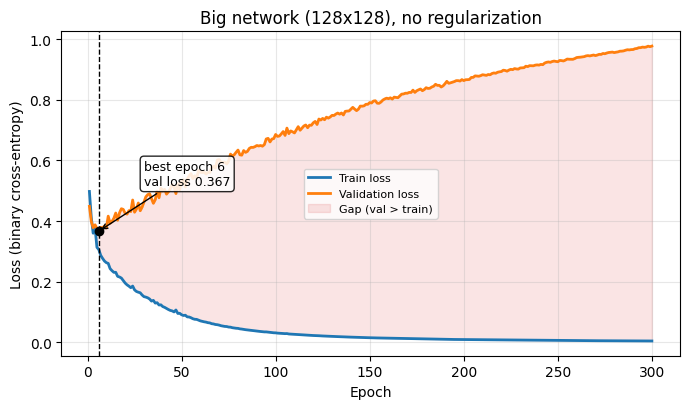

In [4]:
def plot_curves(ax, tl, vl, title):
    ep = np.arange(1, len(tl) + 1); best = int(np.argmin(vl))             
    ax.plot(ep, tl, color='tab:blue', lw=2, label='Train loss')
    ax.plot(ep, vl, color='tab:orange', lw=2, label='Validation loss')
    ax.fill_between(ep, tl, vl, where=np.array(vl) > np.array(tl), color='tab:red', alpha=0.12, label='Gap (val > train)')
    ax.axvline(best + 1, color='k', ls='--', lw=1)
    ax.scatter([best + 1], [vl[best]], color='k', zorder=5)
    ax.annotate(f'best epoch {best + 1}\nval loss {vl[best]:.3f}', xy=(best + 1, vl[best]),
                xytext=(best + 1 + len(tl) * 0.08, vl[best] + (max(vl) - min(vl)) * 0.25),
                arrowprops=dict(arrowstyle='->'), fontsize=9, bbox=dict(boxstyle='round', fc='white', alpha=0.85))
    ax.set_xlabel('Epoch'); ax.set_ylabel('Loss (binary cross-entropy)'); ax.set_title(title)
    ax.grid(alpha=0.3); ax.legend(loc='best', fontsize=8)

fig, ax = plt.subplots(figsize=(7, 4.2))
plot_curves(ax, train_losses, val_losses, 'Big network (128x128), no regularization')
fig.tight_layout(); plt.show()

In [5]:
def smooth(v, w=5):                                                     
    v = np.array(v); return np.array([v[max(0, i - w + 1):i + 1].mean() for i in range(len(v))])

def slope(v):                                                          
    x = np.arange(len(v)); return ((x - x.mean()) * (v - np.mean(v))).sum() / ((x - x.mean()) ** 2).sum()

def diagnose(tl, vl):
    tl, vl = np.array(tl), np.array(vl); best = int(np.argmin(vl)); sv = smooth(vl)
    rise = np.where(sv[best:] > sv[best] * 1.05)[0]                     
    return dict(best_epoch=best + 1, best_val=vl[best], final_val=vl[-1], final_train=tl[-1],
                val_increase_pct=100 * (vl[-1] / vl[best] - 1),
                overfit_starts=(best + rise[0] + 1) if len(rise) else None,
                val_slope_last50=slope(vl[-50:]), train_slope_last50=slope(tl[-50:]),
                gap_end=vl[-1] - tl[-1], gap_at_best=vl[best] - tl[best])

for k, v in diagnose(train_losses, val_losses).items():
    print(f'{k:20s}', None if v is None else round(float(v), 4))

best_epoch           6.0
best_val             0.3668
final_val            0.9768
final_train          0.0049
val_increase_pct     166.3251
overfit_starts       15.0
val_slope_last50     0.001
train_slope_last50   -0.0
gap_end              0.9719
gap_at_best          0.0607


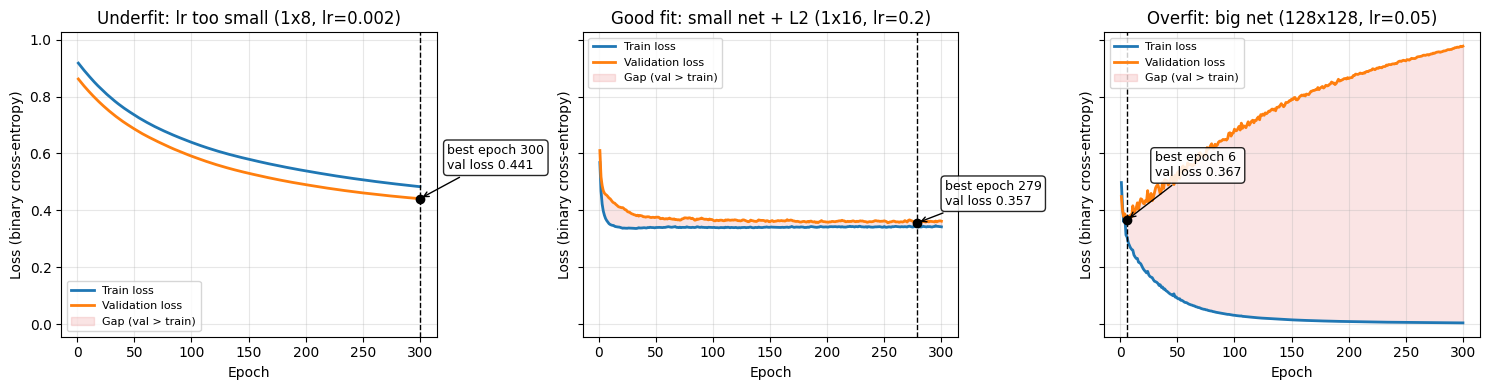

Underfit: lr too small (1x8, lr=0.002)     best ep 300 | best val 0.441 | final train 0.483 | final val 0.441 | val slope(last 50) -0.00040
Good fit: small net + L2 (1x16, lr=0.2)    best ep 279 | best val 0.357 | final train 0.342 | final val 0.362 | val slope(last 50) +0.00002
Overfit: big net (128x128, lr=0.05)        best ep   6 | best val 0.367 | final train 0.005 | final val 0.977 | val slope(last 50) +0.00099


In [6]:
setups = {'Underfit: lr too small (1x8, lr=0.002)': dict(hidden=(8,), lr=0.002),
          'Good fit: small net + L2 (1x16, lr=0.2)': dict(hidden=(16,), lr=0.2, wd=0.05),
          'Overfit: big net (128x128, lr=0.05)': dict(hidden=(128, 128), lr=0.05)}
runs = {name: train(**cfg) for name, cfg in setups.items()}

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (name, (tl, vl)) in zip(axes, runs.items()): plot_curves(ax, tl, vl, name)
fig.tight_layout(); plt.show()

for name, (tl, vl) in runs.items():
    d = diagnose(tl, vl)
    print(f"{name:42s} best ep {d['best_epoch']:3d} | best val {d['best_val']:.3f} | final train {d['final_train']:.3f} | final val {d['final_val']:.3f} | val slope(last 50) {d['val_slope_last50']:+.5f}")

In [7]:
rows = []
for s in range(5):
    tl, vl = train(hidden=(128, 128), lr=0.05, seed=s); d = diagnose(tl, vl)
    rows.append((d['best_epoch'], d['best_val'], d['final_val'], d['val_increase_pct']))
rows = np.array(rows)
print(f"best epoch      : {rows[:,0].mean():.0f} +- {rows[:,0].std():.0f}   (har seed: {rows[:,0].astype(int).tolist()})")
print(f"best val loss   : {rows[:,1].mean():.3f} +- {rows[:,1].std():.3f}")
print(f"final val loss  : {rows[:,2].mean():.3f} +- {rows[:,2].std():.3f}")
print(f"val loss increase after best epoch: {rows[:,3].mean():.0f}% +- {rows[:,3].std():.0f}%")

best epoch      : 5 +- 2   (har seed: [6, 6, 6, 5, 2])
best val loss   : 0.368 +- 0.011
final val loss  : 0.967 +- 0.072
val loss increase after best epoch: 162% +- 15%


In [9]:
RUN_KERAS = False
if RUN_KERAS:
    import tensorflow as tf
    model = tf.keras.Sequential([tf.keras.layers.Input((Xtr.shape[1],)),
                                 tf.keras.layers.Dense(128, activation='relu'),
                                 tf.keras.layers.Dense(128, activation='relu'),
                                 tf.keras.layers.Dense(1, activation='sigmoid')])
    model.compile(optimizer=tf.keras.optimizers.SGD(0.05), loss='binary_crossentropy')
    history = model.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=300, batch_size=32, verbose=0)
    keras_train = history.history['loss']              # <- manually extract (koi Keras plot function nahi)
    keras_val = history.history['val_loss']
    fig, ax = plt.subplots(figsize=(7, 4.2)); plot_curves(ax, keras_train, keras_val, 'Keras model'); plt.show()